In [2]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [5]:
work_folder = 'edge_spen'
saving_folder = 'l9'
os.chdir(work_folder)

In [6]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [7]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])

In [8]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))
from ppo_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ppo_ants = PPO_ants( env,
                 gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                 clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                 state_dim, action_dim, clip_grad, use_gae=True, lam=0.95)
        

In [9]:
load_from_run = True
ppo_ants.setup_networks()
best_weigths = False

if load_from_run and best_weigths:
    ppo_ants.load_weights(saving_folder + '/weights/best_weights')
else:
    if load_from_run:
        ppo_ants.load_weights(saving_folder + '/weights')
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/critic_weights.pth", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/actor_weights.pth", weights_only=True))

In [10]:
seed = int(saving_folder[-1])

In [11]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
n_special_list = [5,10,15,60]
policies = [0,1,2,3,4,5,6,7,8,9]

In [11]:
import csv
import os
import numpy as np
import torch
import random

for n_special in n_special_list:

    for seed in policies:
        
        saving_folder = 'l' + str(seed)

        env = Ants(n, Lx, Ly, delta_list[0], beta_list[0], decay_rate, eta, eta_special,
                    tmax, n_special, t_transient, vision=state_dim[-1])
                
        ppo_ants = PPO_ants( env,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad, use_gae=True, lam=0.95)

        ppo_ants.setup_networks()
        ppo_ants.load_weights(saving_folder + '/weights')

        filename = "component_reward.csv"

        # Intestazioni delle colonne
        header = [
            "seed", "sim_seed", "n_special", "beta", "delta",
            "pop",
            "pod",
            "rew_mean",
            "len_rew_mean",
            "edge_pen_mean"
        ]

        # Se il file non esiste, scrivi l'header
        if not os.path.exists(filename):
            with open(filename, "w", newline="") as f:
                writer = csv.writer(f)
                writer.writerow(header)
        
        for i,beta in enumerate(beta_list):
            for j,delta in enumerate(delta_list):
                sim_seed = i*len(delta_list) + j
                np.random.seed(sim_seed)
                torch.manual_seed(sim_seed)
                random.seed(sim_seed)

                ppo_ants.env.reset_objects()
                ppo_ants.env.delta[:] = delta
                ppo_ants.env.beta[:] = beta
                
                ppo_ants.env.transient()
                state = ppo_ants.get_state()

                reward_list = []
                len_rew_list = []
                edge_pen_list = []

                while ppo_ants.env.t < ppo_ants.env.tmax:
                    actions = ppo_ants.policy(state)
                    next_state, reward, done = ppo_ants.execute_action(actions)
                    state = next_state.copy()
                    rewards_for_components, pop, pod = ppo_ants.global_reward()
                    rewards_for_components = np.array(rewards_for_components)
                    reward_list.append(rewards_for_components[:,0])
                    len_rew_list.append(rewards_for_components[:,1])
                    edge_pen_list.append(rewards_for_components[:,2])

                '''rewards = rewards_for_components[:,0]
                rew = np.mean(rewards)
                len_rew = np.mean(rewards_for_components[:,1])
                edge_pen = np.mean(rewards_for_components[:,2])'''

                print(ppo_ants.env.delta[-1], ppo_ants.env.beta[-1])


                # Scriviamo direttamente nel CSV
                row_data = [
                    seed, sim_seed, n_special, ppo_ants.env.beta[-1], ppo_ants.env.delta[-1],
                    pop,
                    pod,
                    reward_list,
                    len_rew_list,
                    edge_pen_list
                ]

                with open(filename, "a", newline="") as f:
                    writer = csv.writer(f)
                    writer.writerow(row_data)

        print(f"Risultati salvati per seed {seed}")


0.3 3.5
0.4 3.5
0.5 3.5
0.6 3.5
0.7 3.5
0.8 3.5
0.3 4.5
0.4 4.5
0.5 4.5
0.6 4.5
0.7 4.5
0.8 4.5
0.3 5.5
0.4 5.5
0.5 5.5
0.6 5.5
0.7 5.5
0.8 5.5
0.3 6.5
0.4 6.5
0.5 6.5
0.6 6.5
0.7 6.5
0.8 6.5
0.3 7.5
0.4 7.5
0.5 7.5
0.6 7.5
0.7 7.5
0.8 7.5
0.3 8.5
0.4 8.5
0.5 8.5
0.6 8.5
0.7 8.5
0.8 8.5
0.3 9.5
0.4 9.5
0.5 9.5
0.6 9.5
0.7 9.5
0.8 9.5
Risultati salvati per seed 0
0.3 3.5
0.4 3.5
0.5 3.5
0.6 3.5
0.7 3.5
0.8 3.5
0.3 4.5
0.4 4.5
0.5 4.5
0.6 4.5
0.7 4.5
0.8 4.5
0.3 5.5
0.4 5.5
0.5 5.5
0.6 5.5
0.7 5.5
0.8 5.5
0.3 6.5
0.4 6.5
0.5 6.5
0.6 6.5
0.7 6.5
0.8 6.5
0.3 7.5
0.4 7.5
0.5 7.5
0.6 7.5
0.7 7.5
0.8 7.5
0.3 8.5
0.4 8.5
0.5 8.5
0.6 8.5
0.7 8.5
0.8 8.5
0.3 9.5
0.4 9.5
0.5 9.5
0.6 9.5
0.7 9.5
0.8 9.5
Risultati salvati per seed 1
0.3 3.5
0.4 3.5
0.5 3.5
0.6 3.5
0.7 3.5
0.8 3.5
0.3 4.5
0.4 4.5
0.5 4.5
0.6 4.5
0.7 4.5
0.8 4.5
0.3 5.5
0.4 5.5
0.5 5.5
0.6 5.5
0.7 5.5
0.8 5.5
0.3 6.5
0.4 6.5
0.5 6.5
0.6 6.5
0.7 6.5
0.8 6.5
0.3 7.5
0.4 7.5
0.5 7.5
0.6 7.5
0.7 7.5
0.8 7.5
0.3 8.5
0.4 8.5
0.5 8.5
0.6 8.

In [12]:
# load the dataset
import pandas as pd
load = True
if load:
    dfbm = pd.read_csv("component_reward.csv")

In [13]:
dfbm['rew_mean'] = dfbm['rew_mean'].apply(lambda x: eval(x, {"array": np.array}))
dfbm['len_rew_mean'] = dfbm['len_rew_mean'].apply(lambda x: eval(x, {"array": np.array}))
dfbm['edge_pen_mean'] = dfbm['edge_pen_mean'].apply(lambda x: eval(x, {"array": np.array}))

In [14]:
rewards = []
for i in range(len(dfbm)):
    rew_to_sum = []
    for rew_t in dfbm.at[i, 'rew_mean']:
        rew_to_sum.append(np.sum(rew_t))
    rewards.append(np.mean(rew_to_sum))

In [15]:
dfbm

,seed,sim_seed,n_special,beta,delta,pop,pod,rew_mean,len_rew_mean,edge_pen_mean
0,0,0,30,3.5,0.3,0.975847,0.800000,"[[-2.2795833, -1.09919059, -1.09919059, -1.734...","[[1.0, 0.09375, 0.09375, 0.65625, 0.0625, 0.37...","[[-2.28488372, -1.0, -1.0, -1.7, -1.0, -1.4545..."
1,0,1,30,3.5,0.4,0.955875,0.493333,"[[-2.01951086, -2.29858063, -1.11618886, -2.05...","[[1.0, 1.0, 0.125, 1.0, 1.0, 0.0625, 0.09375, ...","[[-2.0, -2.27906977, -1.0, -2.03508772, -1.822..."
2,0,2,30,3.5,0.5,0.934492,0.373333,"[[-1.83383434, -1.95835878, -2.061381, -1.6696...","[[0.3125, 0.375, 1.0, 0.1875, 0.53125, 0.1875,...","[[-1.77777778, -1.90909091, -2.08, -1.6, -1.68..."
3,0,3,30,3.5,0.6,0.945854,0.233333,"[[-1.41387616, -1.27995759, -1.39281395, -1.85...","[[0.875, 0.1875, 0.5625, 1.0, 0.40625, 0.09375...","[[-1.40740741, -1.2, -1.35294118, -1.85714286,..."
4,0,4,30,3.5,0.7,0.930274,-0.006667,"[[-1.83248661, -1.72174464, -1.16691137, -2.14...","[[1.0, 1.0, 0.0625, 0.71875, 0.0625, 1.0, 0.09...","[[-1.76190476, -1.65116279, -1.0, -2.04545455,..."
...,...,...,...,...,...,...,...,...,...,...
2095,9,37,60,9.5,0.4,1.000000,1.000000,"[[-1.4199012, -1.18501535, -0.86643954, -1.056...","[[1.0, 0.21875, 0.15625, 1.0, 0.15625, 0.25, 0...","[[-1.75268817, -1.33333333, -1.0, -1.38888889,..."
2096,9,38,60,9.5,0.5,0.999266,1.000000,"[[-1.30542628, -1.52573616, -1.43042426, -0.89...","[[0.5625, 1.0, 1.0, 0.0625, 0.0625, 0.21875, 0...","[[-1.52941176, -1.85393258, -1.75862069, -1.0,..."
2097,9,39,60,9.5,0.6,0.999982,0.993333,"[[-1.28199597, -1.2462784, -1.35688655, -1.036...","[[0.96875, 0.28125, 0.71875, 0.09375, 1.0, 0.1...","[[-1.43333333, -1.25, -1.45454545, -1.0, -1.59..."
2098,9,40,60,9.5,0.7,0.999940,0.993333,"[[-1.52230805, -2.07095915, -1.28956814, -1.57...","[[1.0, 0.3125, 1.0, 1.0, 0.1875, 0.3125, 0.156...","[[-1.70212766, -2.11111111, -1.46938776, -1.75..."


In [18]:
n_special_list = [5,10,15,30,60]
for n_s in n_special_list:
    dfbm_i = dfbm[dfbm['n_special'] == n_s].reset_index(drop=True)

    pop = []
    for i in range(len(dfbm_i)):
        pop.append(np.mean(dfbm_i.at[i, 'pop']))
    
    pod = []
    for i in range(len(dfbm_i)):
        pod.append(np.mean(dfbm_i.at[i, 'pod']))
    
    rewards = []
    for i in range(len(dfbm_i)):
        rew_to_sum = []
        for rew_t in dfbm_i.at[i, 'rew_mean']:
            rew_to_sum.append(np.sum(rew_t))
        rewards.append(np.mean(rew_to_sum))

    lazt_50_rewards = []
    for i in range(len(dfbm_i)):
        rew_to_sum = []
        for rew_t in dfbm_i.at[i, 'rew_mean']:
            rew_to_sum.append(np.sum(rew_t))
        lazt_50_rewards.append(np.mean(rew_to_sum[-50:]))

    '''len_rewards = []
    for i in range(len(dfbm_i)):
        len_rew_to_sum = []
        for len_rew_t in dfbm_i.at[i, 'len_rew_mean']:
            len_rew_to_sum.append(np.mean(len_rew_t))
        len_rewards.append(np.mean(len_rew_to_sum))

    edge_penalties = []
    for i in range(len(dfbm_i)):
        edge_pen_to_sum = []
        for edge_pen_t in dfbm_i.at[i, 'edge_pen_mean']:
            edge_pen_to_sum.append(np.mean(edge_pen_t))
        edge_penalties.append(np.mean(edge_pen_to_sum))'''
    
    print(f"n_special: {n_s}")
    print('average pop', np.mean(pop))
    print('average pod', np.mean(pod))
    print('avergae rewards', np.mean(rewards, axis=0))
    print('last 50 rewards', np.mean(lazt_50_rewards, axis=0))
    

n_special: 5
average pop 0.8912999299653022
average pod 0.690920634920635
avergae rewards -3.256492980146155
last 50 rewards -2.1607162338192762
n_special: 10
average pop 0.940811134653215
average pod 0.7106190476190477
avergae rewards -3.0336464510342998
last 50 rewards -1.783004847212152
n_special: 15
average pop 0.9580290612132152
average pod 0.7063333333333333
avergae rewards -2.9236845731065753
last 50 rewards -1.5910521334431857
n_special: 30
average pop 0.9770311598042664
average pod 0.7023015873015874
avergae rewards -2.7129539448874356
last 50 rewards -1.522389997189527
n_special: 60
average pop 0.9869075705260159
average pod 0.6980634920634922
avergae rewards -2.6330971203303686
last 50 rewards -1.5945588568977211


In [ ]:
print('avergae rewards', np.mean(rewards, axis=0))
print('std rewards', np.std(rewards, axis=0))
print('last 50 rewards', np.mean(lazt_50_rewards, axis=0))
print('std last 50 rewards', np.std(lazt_50_rewards, axis=0))

In [30]:
n_seeds = len(dfbm['seed'].unique())

In [26]:
rewards = np.array(rewards).reshape(n_seeds, len(beta_list), len(delta_list))
len_rewards = np.array(len_rewards).reshape(n_seeds, len(beta_list), len(delta_list))
edge_penalties = np.array(edge_penalties).reshape(n_seeds, len(beta_list), len(delta_list))

In [28]:
rewards.shape

(1, 7, 6)

avergae rewards -2.2440712447104763
std rewards 0.6334224471339887
last 50 rewards -1.3669308390857144
std last 50 rewards 0.6848285414292081


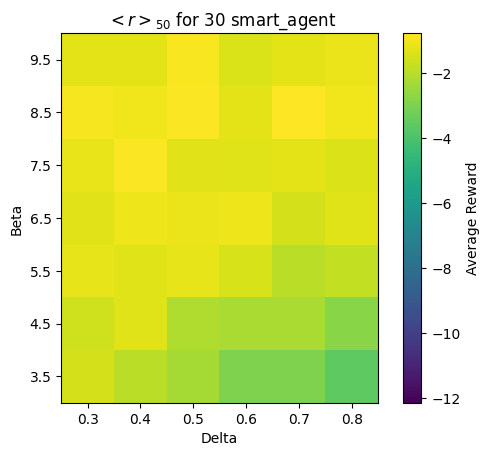

In [19]:
rew_avg_by_seed = np.mean(rewards, axis=0)
plt.imshow(rew_avg_by_seed, cmap='viridis', origin='lower',
            vmin=-12.1354920402, vmax=max(rew_avg_by_seed.flatten()))
plt.colorbar(label='Average Reward')
plt.xlabel('Delta')
plt.ylabel('Beta')
plt.title(r' $<r>_{50}$ for 30 smart_agent')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

In [20]:
print(np.mean(rew_avg_by_seed))

-1.5223899971895267


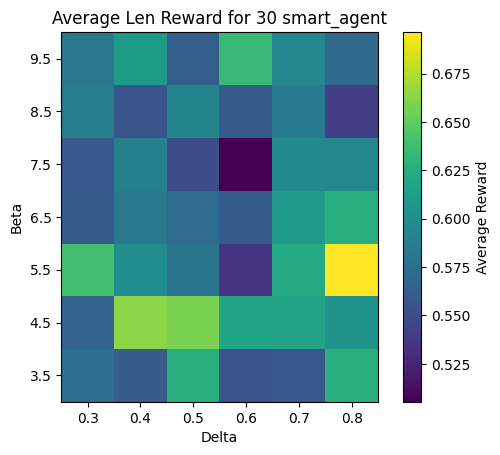

In [120]:
rew_len_avg_by_seed = np.mean(len_rewards, axis=0)
plt.imshow(rew_len_avg_by_seed, cmap='viridis', origin='lower',
            vmin=min(rew_len_avg_by_seed.flatten()), vmax=max(rew_len_avg_by_seed.flatten()))
plt.colorbar(label='Average Reward')
plt.xlabel('Delta')
plt.ylabel('Beta')
plt.title('Average Len Reward for 30 smart_agent')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

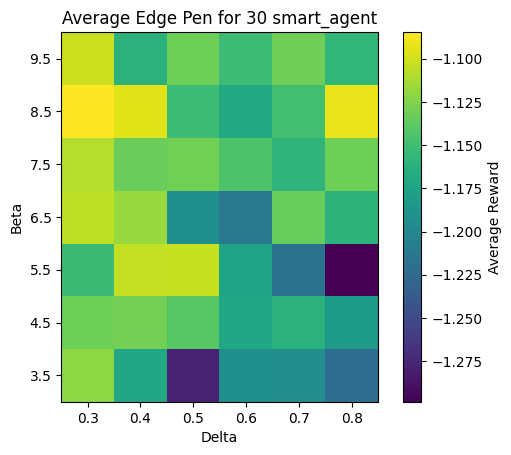

In [121]:
import matplotlib.pyplot as plt
edge_pen0 = np.mean(edge_penalties, axis=0)
plt.imshow(edge_pen0, cmap='viridis', origin='lower',
            vmin=min(edge_pen0.flatten()), vmax=max(edge_pen0.flatten()))
plt.colorbar(label='Average Reward')
plt.xlabel('Delta')
plt.ylabel('Beta')
plt.title('Average Edge Pen for 30 smart_agent')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

In [19]:
# average over n_special with standard deviation and skip the seeds column
dfbm = dfbm[dfbm['seed'] == 0]
df=dfbm.groupby(['n_special']).agg(['mean', 'std']).drop(columns=['seed', 'sim_seed','beta', 'delta'])

TypeError: agg function failed [how->mean,dtype->object]

In [15]:
df.style.format("{:.2f}")

In [18]:
raw_mean_df = dfbm.groupby(['n_special', 'beta', 'delta']).lastr_mean.mean().unstack().unstack()
std_mean_df = dfbm.groupby(['n_special', 'beta', 'delta']).lastr_mean.std().unstack().unstack()

raw_mean_df30 = raw_mean_df.loc[30]
std_mean_df30 = std_mean_df.loc[30]

raw_mean_arr30 = np.array(raw_mean_df30.values).reshape(len(delta_list), len(beta_list))
std_mean_arr30 = np.array(std_mean_df30.values).reshape(len(delta_list), len(beta_list))

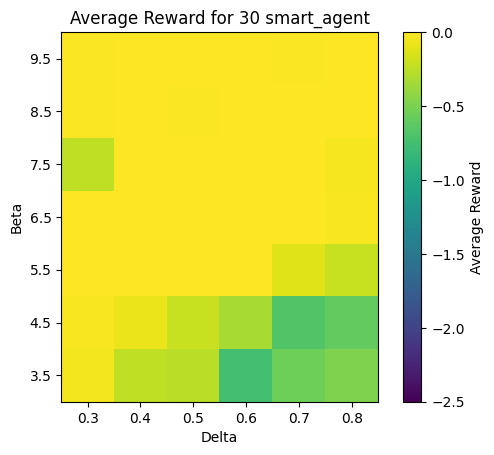

In [20]:
plt.imshow(raw_mean_arr30.T, cmap='viridis', origin='lower', vmin=-2.5, vmax=0)
plt.colorbar(label='Average Reward')
plt.xlabel('Delta')
plt.ylabel('Beta')
plt.title('Average Reward for 30 smart_agent')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()